## Regressions

<img src="../data/regression-gif.gif" alt="alt text" width="300" height="200">

A regression is a way to describe how two (or more) things are related to each other. This notebook performs two simple regressions on a small data set: a linear regression and a logistic regression. The notebook was adapted from [investigate.ai](https://investigate.ai/regression/) and [Dr. Tehreem Qasim](https://www.kaggle.com/code/tehreemkhan111/simple-linear-regression).



In [2]:
import pandas as pd

### Performing a linear regression
First we will load our data

In [4]:
df = pd.read_csv('../data/Salary_Data.csv')
print(len(df))
df.head()

30


,YearsExperience,Salary,promoted
0,1.1,39343.0,0
1,1.3,46205.0,0
2,1.5,37731.0,0
3,2.0,43525.0,1
4,2.2,39891.0,0


Using the library statsmodels we can run linear regressions with dataframes. 

In [ ]:
%pip install statsmodels

In [7]:
import statsmodels.api as sm

Below we do two things: 
We define `YearsExperience` as the dependent variable. 

Ordinary Least Squares function from the statsmodels library. OLS is a common technique used in analyzing linear regression. In brief, it compares the difference between individual points in your data set and the predicted best fit line to measure the amount of error produced. (Source: [Medium](https://medium.com/swlh/interpreting-linear-regression-through-statsmodels-summary-4796d359035a)).

In [8]:
X = df["YearsExperience"]
y = df["Salary"]

# OLS
model = sm.OLS(y, X)
results = model.fit()

#### Examining our results

We stored our regression in a variable called `results`. Now we can look at the results but using the `.summary()` function to print out the entire regression result.



In [9]:
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                 Salary   R-squared (uncentered):                   0.973
Model:                            OLS   Adj. R-squared (uncentered):              0.972
Method:                 Least Squares   F-statistic:                              1048.
Date:                Sun, 01 Nov 2026   Prob (F-statistic):                    2.56e-24
Time:                        11:18:36   Log-Likelihood:                         -327.28
No. Observations:                  30   AIC:                                      656.6
Df Residuals:                      29   BIC:                                      658.0
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
===================================================================================
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
YearsExperience  1.325e+04    409.401     32.376      0.000    1.24e+04    1.41e+04
==============================================================================
Omnibus:                        0.610   Durbin-Watson:                   0.323
Prob(Omnibus):                  0.737   Jarque-Bera (JB):                0.671
Skew:                          -0.121   Prob(JB):                        0.715
Kurtosis:                       2.308   Cond. No.                         1.00
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

### How to interpret your results


Our dependent variable is **Salary**, meaning we were interested in how much our Salary is dependent on the number of years. The information below is a summary of this [Medium post](https://medium.com/swlh/interpreting-linear-regression-through-statsmodels-summary-4796d359035a), this [Mediun post](https://medium.com/analytics-vidhya/how-to-interpret-result-from-linear-regression-3f7ae7679ef9) and this [Medium post](https://blog.dailydoseofds.com/p/statsmodel-regression-summary-will).

<img src="../data/regression_illustration.png" alt="alt text" width="800">

Here are some of the things we want to pay special attention to:
- `R-squared`: R-squared is possibly the most important measurement produced by this summary. R-squared is the measurement of how much of the independent variable is explained by changes in our dependent variables. In percentage terms, 0.957 would mean our model explains 95.7% of the change in our ‘Salary’ variable.
- `Adj. R-squared`: This is the modified version of R-squared which is adjusted for the number of variables in the regression. It increases only when an additional variable adds to the explanatory power to the regression.
- `Coefficients`: These show the estimated effect of each independent variable on the dependent variable.
- `P-values`: These indicate the statistical significance of each coefficient. These indicate the statistical significance of each coefficient. Generally, a p-value < 0.05 is considered statistically significant.

### Plotting our linear regression
In the next few lines we will plot our linear regression. It can help us understand what the linear regression above is doing.

In [10]:
from matplotlib import pyplot as plt

Text(0, 0.5, 'Salary')

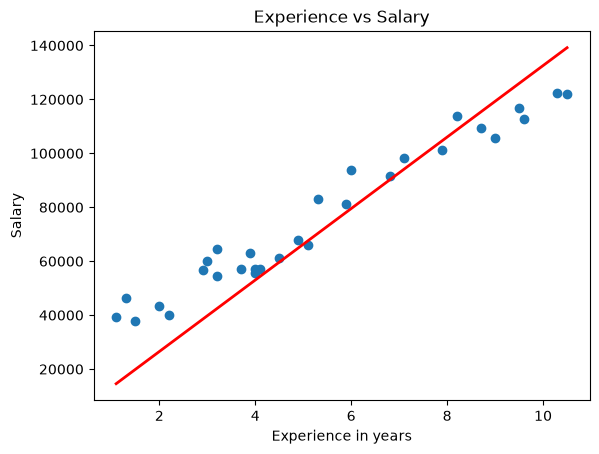

In [11]:
# create the scatterplot
plt.scatter(df["YearsExperience"], df["Salary"])

# create the regression line
# this uses df['YearsExperience'] for the x-axis and results.predict() for the y-axis
plt.plot(df['YearsExperience'], 
         results.predict(), 
         color='red', 
         linewidth=2, 
         label='Regression line'
)

# customize the plot
plt.title("Experience vs Salary")
plt.xlabel("Experience in years")
plt.ylabel("Salary")


### Logistic regression

Our dataset has two columns:

* Number of years
* Whether someone was promoted or not. 1 means yes, 0 means no

We want to ask a simple question using this data: **how does length of experience influence whether someone gets promoted or not?** Since being promoted is a yes/no question, we get to use **logistic regression**.

In [12]:
import statsmodels.formula.api as smf

#how does length of experience influence whether someone gets promoted or not?
model = smf.logit(formula='promoted ~ YearsExperience', data=df)
results = model.fit()

Optimization terminated successfully.
         Current function value: 0.635838
         Iterations 5


### How to interpret your results

In [14]:
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:               promoted   No. Observations:                   30
Model:                          Logit   Df Residuals:                       28
Method:                           MLE   Df Model:                            1
Date:                Sun, 01 Nov 2026   Pseudo R-squ.:                 0.05523
Time:                        11:19:12   Log-Likelihood:                -19.075
converged:                       True   LL-Null:                       -20.190
Covariance Type:            nonrobust   LLR p-value:                    0.1353
===================================================================================
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept          -0.6752      0.826     -0.817      0.414      -2.294       0.944
YearsExperience     0.2107      0.148      1.423      0.155      -0.079       0.501
===================================================================================
"""

### Can GPA predict SAT score?

In [15]:
school_data = pd.read_csv('../data/sat_gpa.csv')


In [17]:
print(len(school_data))
school_data.head()

100


,SAT,GPA
0,1714,2.40
1,1664,2.52
2,1760,2.54
3,1685,2.74
4,1693,2.83


In [ ]:
X = school_data["GPA"]
y = school_data["SAT"]

# The constant column allows statsmodels to estimate B0, the intercept.
X = sm.add_constant(X)

# OLS
model = sm.OLS(y, X)
results = model.fit()

In [23]:
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                    SAT   R-squared:                       0.375
Model:                            OLS   Adj. R-squared:                  0.369
Method:                 Least Squares   F-statistic:                     58.86
Date:                Mon, 02 Nov 2026   Prob (F-statistic):           1.26e-11
Time:                        07:35:42   Log-Likelihood:                -579.94
No. Observations:                 100   AIC:                             1164.
Df Residuals:                      98   BIC:                             1169.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1043.0474    105.593      9.878      0.000     833.501    1252.594
GPA          240.3549     31.330      7.672      0.000     178.182     302.528
==============================================================================
Omnibus:                        0.326   Durbin-Watson:                   2.349
Prob(Omnibus):                  0.849   Jarque-Bera (JB):                0.379
Skew:                          -0.132   Prob(JB):                        0.828
Kurtosis:                       2.854   Cond. No.                         48.0
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

Text(0, 0.5, 'SAT')

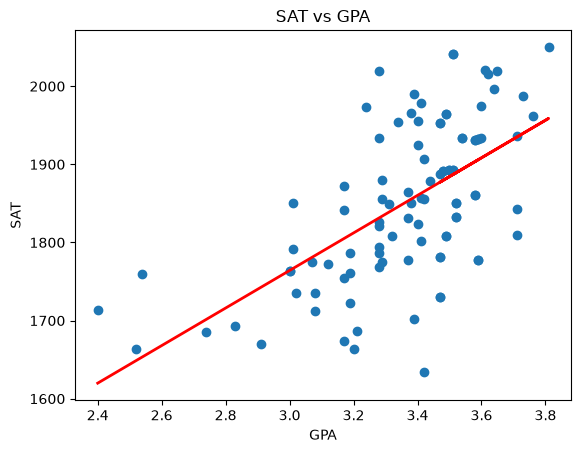

In [24]:
# create the scatterplot
plt.scatter(school_data["GPA"], school_data["SAT"])

# create the regression line
# this uses df['YearsExperience'] for the x-axis and results.predict() for the y-axis
plt.plot(school_data["GPA"], 
         results.predict(), 
         color='red', 
         linewidth=2, 
         label='Regression line'
)

# customize the plot
plt.title("SAT vs GPA")
plt.xlabel("GPA")
plt.ylabel("SAT")

In [27]:
real_estate_data = pd.read_csv('../data/real_estate_dataset.csv')
len(real_estate_data)


500

In [28]:
real_estate_data.head()

,ID,Square_Feet,Num_Bedrooms,Num_Bathrooms,Num_Floors,Year_Built,Has_Garden,Has_Pool,Garage_Size,Location_Score,Distance_to_Center,Price
0,1,143.635030,1,3,3,1967,1,1,48,8.297631,5.935734,602134.816747
1,2,287.678577,1,2,1,1949,0,1,37,6.061466,10.827392,591425.135386
2,3,232.998485,1,3,2,1923,1,0,14,2.911442,6.904599,464478.696880
3,4,199.664621,5,2,2,1918,0,0,17,2.070949,8.284019,583105.655996
4,5,89.004660,4,3,3,1999,1,0,34,1.523278,14.648277,619879.142523


Question: What factors explain differences in housing prices, and how well can we predict the price of a house using its characteristics?

Let's start simple with the question... Does house size affect price?

Dependent variable (Y): Price
Independent variable (X): Square_Feet

Price= B0+B1(SquareFeet )
The intercept tells us that when square footage is zero, the predicted house price is TKTK (in whatever units the dataset uses).

So for example, if we have the equation: 
Price = 8.49 + 150 sq ft. ...

The intercept tells us that when square footage is zero, the predicted house price is 8.49 (in whatever units the dataset uses).

For every additional square foot, the predicted house price increases by 150 units, on average.


In [ ]:
# TKTKT CODE HERE

# TKTK INTERPRETATION HERE

Does house size still matter when we control for the number of bedrooms and bathrooms?

Variables:

Y: Price
X1: Square_Feet
X2: Num_Bedrooms
X3: Num_Bathrooms

In [29]:
# Run multiple linear regression
model = smf.ols("Price ~ Square_Feet + Num_Bedrooms + Num_Bathrooms", data=real_estate_data).fit()

# Display results
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                  Price   R-squared:                       0.700
Model:                            OLS   Adj. R-squared:                  0.698
Method:                 Least Squares   F-statistic:                     385.7
Date:                Mon, 02 Nov 2026   Prob (F-statistic):          3.29e-129
Time:                        07:58:14   Log-Likelihood:                -6265.0
No. Observations:                 500   AIC:                         1.254e+04
Df Residuals:                     496   BIC:                         1.255e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept      2.055e+05   1.26e+04     16.270

Your model explains 70% of the variation in house prices, and all three explanatory variables are statistically significant.